# 10 — Time to termination (competing risks)

**Question:** Once a trial starts, how soon does it end in termination for low enrollment, termination for another
reason, or completion? Later sections ask which start-time characteristics change the risk of each.

A trial that completes, or stops for another reason, can no longer be terminated for low enrollment. These are
competing risks, so 1 − Kaplan–Meier would overstate the risk of each outcome. We estimate cumulative incidence
(Aalen–Johansen) instead, and use cause-specific Cox models to see which start-time features change each risk
(section 5).

**Stop reasons are still v0**, the keyword rules in `scripts/03_build_dataset.py`. Once notebook 07 validates the
LLM labels, point `REASON_COL` at the new column and rerun.

**Inputs:** `data/processed/trials.parquet` (status, stop reason, start-time features),
`data/raw/studies.parquet` (completion and verification dates), and the feature files from notebooks 03
(`eligibility_features.parquet`) and 04 (`disease_area.parquet`).

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "notebooks" / "figures"

REASON_COL = "stop_reason"     # v0 keyword labels
UNKNOWN_HANDLING = "censor"    # "censor" or "exclude"; see section 3
MONTH = 30.4375
OUTCOMES = {1: "terminated: enrollment", 2: "terminated: other", 3: "completed"}
COLORS = {1: "#2a78d6", 2: "#eb6834"}

trials = pd.read_parquet(ROOT / "data/processed/trials.parquet",
                         columns=["nct_id", "overall_status", REASON_COL, "phase", "lead_sponsor_class", "start_year"])
dates = pd.read_parquet(ROOT / "data/raw/studies.parquet",
                        columns=["nct_id", "start_date", "completion_date", "completion_date_type", "verification_date"])
for c in ["start_date", "completion_date", "verification_date"]:
    dates[c] = pd.to_datetime(dates[c])
df = trials.merge(dates, on="nct_id", how="left")
print(f"{len(df):,} trials")

231,776 trials


## 1. Outcome and time

| Status | Role | End of follow-up |
|---|---|---|
| TERMINATED, stop reason `enrollment` | outcome 1 | actual completion date |
| TERMINATED, any other reason (including none given) | outcome 2 | actual completion date |
| COMPLETED | outcome 3 | actual completion date |
| RECRUITING, ACTIVE_NOT_RECRUITING, ENROLLING_BY_INVITATION, SUSPENDED | censored | verification date |
| UNKNOWN | censored or excluded (section 3) | verification date |
| WITHDRAWN, NOT_YET_RECRUITING | excluded: never enrolled anyone | |

Time runs from `start_date`. The verification date is the last date the sponsor confirmed the trial's status, so a
censored trial is known to be still running up to that date.

For terminated trials, the completion date is when the last participant was seen, which can be months after the
decision to stop. Time to termination is measured to that date.

In [2]:
def build(df, unknown="censor"):
    d = df[~df["overall_status"].isin(["WITHDRAWN", "NOT_YET_RECRUITING"])].copy()
    if unknown == "exclude":
        d = d[d["overall_status"] != "UNKNOWN"]
    status = d["overall_status"]
    ended = status.isin(["COMPLETED", "TERMINATED"])
    d["outcome"] = np.select([status.eq("TERMINATED") & d[REASON_COL].eq("enrollment"),
                              status.eq("TERMINATED"), status.eq("COMPLETED")], [1, 2, 3], default=0)
    actual_end = d["completion_date"].where(d["completion_date_type"].eq("ACTUAL"))
    d["end_date"] = actual_end.where(ended, d["verification_date"])
    d["months"] = (d["end_date"] - d["start_date"]).dt.days / MONTH
    return d

full = build(df, unknown="censor")
flow = full.groupby("overall_status").agg(
    trials=("nct_id", "size"),
    no_actual_end_date=("end_date", lambda s: s.isna().sum()),
    ends_on_or_before_start=("months", lambda s: (s <= 0).sum()),
    analyzed=("months", lambda s: (s > 0).sum()),
)
flow.loc["total"] = flow.sum()
flow

,trials,no_actual_end_date,ends_on_or_before_start,analyzed
overall_status,,,,
ACTIVE_NOT_RECRUITING,4982,0,2,4980
COMPLETED,156707,1732,516,154459
ENROLLING_BY_INVITATION,215,0,1,214
RECRUITING,3017,0,15,3002
SUSPENDED,647,0,57,590
TERMINATED,20039,510,49,19480
UNKNOWN,37943,0,10282,27661
total,223550,2242,10922,210386


Completed and terminated trials without an actual completion date, and records whose end date is on or before
the start date, are dropped. For UNKNOWN trials, "ends on or before start" means the record was last verified before
the trial's planned start, so it was never seen running.

In [3]:
surv = build(df, UNKNOWN_HANDLING)
surv = surv[surv["months"] > 0].copy()
counts = surv["outcome"].map({0: "censored", **OUTCOMES}).value_counts()
print(f"{len(surv):,} trials analyzed (UNKNOWN: {UNKNOWN_HANDLING})")
print(counts.to_string())
print("\nMonths from start to end of follow-up:")
surv.groupby(surv["outcome"].map({0: "censored", **OUTCOMES}))["months"].describe(percentiles=[.25, .5, .75]).round(1)

210,386 trials analyzed (UNKNOWN: censor)
outcome
completed                 154459
censored                   36447
terminated: other          11762
terminated: enrollment      7718

Months from start to end of follow-up:


,count,mean,std,min,25%,50%,75%,max
outcome,,,,,,,,
censored,36447.0,39.7,40.0,0.0,7.6,26.0,64.5,222.1
completed,154459.0,30.5,26.1,0.0,11.0,23.5,43.0,220.2
terminated: enrollment,7718.0,35.8,24.5,0.1,18.0,30.5,48.0,215.5
terminated: other,11762.0,32.5,24.4,0.0,14.0,27.0,45.0,208.0


## 2. Cumulative incidence

The Aalen–Johansen estimate gives the share of trials that have ended each way by a given time, after allowing for
censoring and for the competing outcomes.

In [4]:
def cumulative_incidence(months, outcome):
    counts = pd.crosstab(months, outcome)
    at_risk = counts.sum(axis=1)[::-1].cumsum()[::-1]
    events = counts.drop(columns=0, errors="ignore")
    surv_before = (1 - events.sum(axis=1) / at_risk).cumprod().shift(fill_value=1.0)
    return events.div(at_risk, axis=0).mul(surv_before, axis=0).cumsum()

def at_years(cif, years):
    idx = cif.index.searchsorted(np.asarray(years) * 12, side="right") - 1
    return cif.iloc[idx].set_axis([f"{y} yr" for y in years])

YEARS = [1, 2, 3, 5, 10]
cif = cumulative_incidence(surv["months"], surv["outcome"])
(at_years(cif, YEARS).rename(columns=OUTCOMES) * 100).round(1).T

,1 yr,2 yr,3 yr,5 yr,10 yr
outcome,,,,,
terminated: enrollment,0.5,1.5,2.4,3.6,4.3
terminated: other,1.2,2.7,3.9,5.5,6.5
completed,21.4,40.0,53.6,71.2,84.8


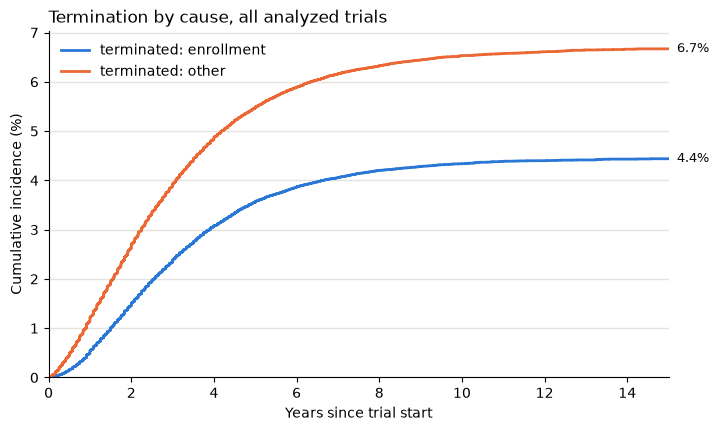

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
END = 15
for k in [1, 2]:
    y = cif[k] * 100
    ax.step(y.index / 12, y, where="post", color=COLORS[k], lw=2, label=OUTCOMES[k])
    end = at_years(cif, [END])[k].iloc[0] * 100
    ax.annotate(f"{end:.1f}%", (END, end), xytext=(6, 0), textcoords="offset points", va="center",
                fontsize=9, color="#0b0b0b", annotation_clip=False)
ax.set_xlim(0, END)
ax.set_ylim(0, None)
ax.set_xlabel("Years since trial start")
ax.set_ylabel("Cumulative incidence (%)")
ax.set_title("Termination by cause, all analyzed trials", loc="left")
ax.legend(frameon=False, loc="upper left")
ax.grid(axis="y", color="#e4e3df", lw=1)
ax.grid(axis="x", visible=False)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.savefig(FIG / "survival_cumulative_incidence.png", bbox_inches="tight", dpi=110)
plt.show()

## 3. Decision: what to do with UNKNOWN trials

ClinicalTrials.gov marks a trial UNKNOWN when it was last reported as recruiting, active or not yet recruiting and
the record hasn't been verified for more than two years. They are 16% of the cohort.

- **Censor at the verification date** (current setting). This uses the time they were known to be running. It
  assumes that trials which stopped reporting end the same way as similar trials that kept reporting. That's
  doubtful: a sponsor that stops updating the record may be more likely to have quietly abandoned the trial, which
  would make the incidence of termination look too low.
- **Exclude them.** This only describes trials whose sponsors kept the record up to date, and throws away the time
  they were known to be running.
- **Make "stopped reporting" a fourth outcome** at the verification date. Then the curves also describe how often
  sponsors abandon the record.

The table shows how much the first two options change the estimates.

In [6]:
compare = {}
for option in ["censor", "exclude"]:
    d = build(df, option)
    d = d[d["months"] > 0]
    c = at_years(cumulative_incidence(d["months"], d["outcome"]), [3, 5, 10])[[1, 2]]
    c.columns = [OUTCOMES[k] for k in c.columns]
    compare[f"{option} ({len(d):,} trials)"] = (c * 100).round(2).stack()
pd.DataFrame(compare)

censor (210,386 trials)  \
3 yr  terminated: enrollment                     2.36   
      terminated: other                          3.89   
5 yr  terminated: enrollment                     3.57   
      terminated: other                          5.48   
10 yr terminated: enrollment                     4.34   
      terminated: other                          6.53   

                              exclude (182,725 trials)  
3 yr  terminated: enrollment                      2.49  
      terminated: other                           4.13  
5 yr  terminated: enrollment                      3.64  
      terminated: other                           5.65  
10 yr terminated: enrollment                      4.31  
      terminated: other                           6.57

**Decision:** _to fill in_

## 4. By phase and sponsor

Five-year cumulative incidence of each kind of termination within each group. `NA` phase means the trial is not a
drug trial with phases (device, behavioral and procedure trials).

In [7]:
def five_year_by(col, min_n=500):
    rows = {}
    for group, d in surv.groupby(surv[col].fillna("missing")):
        if len(d) < min_n:
            continue
        c = at_years(cumulative_incidence(d["months"], d["outcome"]), [5]).iloc[0]
        rows[group] = {"trials": len(d), **{OUTCOMES[k]: round(c.get(k, 0) * 100, 2) for k in [1, 2]}}
    return pd.DataFrame(rows).T.astype({"trials": int}).sort_values(OUTCOMES[1])

by_phase = five_year_by("phase")
display(by_phase)
display(five_year_by("lead_sponsor_class"))

,trials,terminated: enrollment,terminated: other
PHASE1,24376,2.32,7.02
NA,104443,2.87,3.53
PHASE3,19490,3.21,6.82
PHASE2/PHASE3,3634,3.63,7.11
PHASE1/PHASE2,7815,4.34,10.16
EARLY_PHASE1,2681,4.57,6.89
PHASE4,18218,5.19,4.78
PHASE2,29645,5.97,8.74


,trials,terminated: enrollment,terminated: other
OTHER_GOV,4692,2.00,2.34
INDUSTRY,55193,2.61,8.51
FED,2150,3.49,3.92
OTHER,144303,3.97,4.33
NIH,2355,4.55,7.24
NETWORK,1380,5.48,3.41


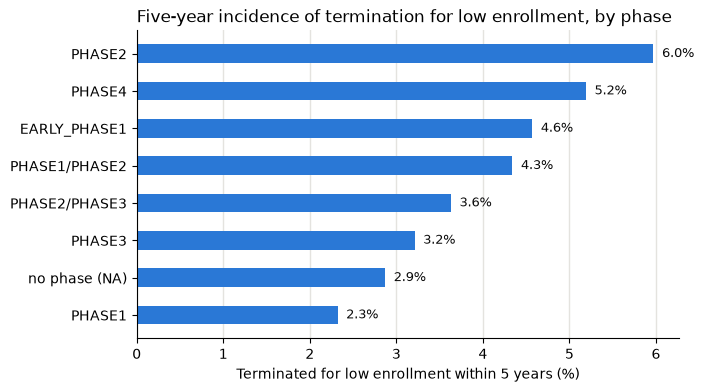

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
y = by_phase[OUTCOMES[1]].astype(float).rename(index={"NA": "no phase (NA)"})
ax.barh(y.index, y, height=0.5, color=COLORS[1])
for i, v in enumerate(y):
    ax.text(v + 0.1, i, f"{v:.1f}%", va="center", fontsize=9, color="#0b0b0b")
ax.set_xlabel("Terminated for low enrollment within 5 years (%)")
ax.set_title("Five-year incidence of termination for low enrollment, by phase", loc="left")
ax.grid(axis="x", color="#e4e3df", lw=1)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.savefig(FIG / "survival_by_phase.png", bbox_inches="tight", dpi=110)
plt.show()

## 5. Cause-specific Cox models

For each outcome, a cause-specific Cox model compares how fast trials that are still running end that way. A hazard
ratio of 1.5 means trials with the feature end that way 50% faster at any point in follow-up. The other two
outcomes count as censoring. The models are stratified by start year, so trials are only compared with trials that
started the same year: follow-up length, registry practice and the timing of COVID all differ by start year.

We fit all three outcomes. A feature can raise the share of trials terminated for low enrollment by raising that
hazard, or by lowering the hazards of the other outcomes, for example by slowing completion. Notebook 05's
logistic model can't tell these apart.

### Features

The features are the three groups in notebook 05's model C (design, disease area, eligibility), with a few changes so
the model can be fitted without a penalty and its coefficients read directly:

- `n_rule_types` is the sum of the `rule_` flags, and `primary_area` and `n_areas` restate the `area_` flags, so they
  are left out.
- Counts are on a log2 scale, so their hazard ratio is per doubling (for example, 8 to 16 exclusion criteria). Ages
  are per 10 years. A blank minimum age means no lower limit and counts as 0; a blank maximum age is coded as
  `has max age` = 0.
- Each categorical feature is compared with its most common level. Levels with fewer than 500 trials are too small
  to estimate, and their trials are dropped.

In [9]:
UNIT_TO_YEARS = {"year": 1, "month": 1/12, "week": 1/52.18, "day": 1/365.25, "hour": 1/8766, "minute": 1/525960}

def age_years(s):
    if not isinstance(s, str):
        return np.nan
    m = re.match(r"\s*([\d.]+)\s*([a-z]+?)s?\s*$", s.lower())
    if not m or m.group(2) not in UNIT_TO_YEARS:
        return np.nan
    return float(m.group(1)) * UNIT_TO_YEARS[m.group(2)]

CAT = ["phase", "lead_sponsor_class", "primary_purpose", "allocation", "masking", "intervention_model", "gender",
       "healthy_volunteers", "has_dmc"]
COUNTS = ["number_of_arms", "n_conditions", "n_interventions", "n_collaborators", "criteria_n_chars",
          "n_inclusion", "n_exclusion"]
MIN_LEVEL = 500

design = pd.read_parquet(ROOT / "data/processed/trials.parquet", columns=[
    "nct_id", "primary_purpose", "allocation", "masking", "intervention_model", "gender", "healthy_volunteers",
    "has_dmc", "number_of_arms", "n_conditions", "n_interventions", "n_collaborators", "criteria_n_chars",
    "minimum_age", "maximum_age"])
elig = pd.read_parquet(ROOT / "data/processed/eligibility_features.parquet")
area = pd.read_parquet(ROOT / "data/processed/disease_area.parquet")
d = surv.merge(design, on="nct_id").merge(elig, on="nct_id").merge(area, on="nct_id")

X = pd.DataFrame(index=d.index)
reference = {}
for c in CAT:
    s = d[c].astype("object").fillna("missing").astype(str)
    reference[c] = s.mode()[0]
    X = X.join(pd.get_dummies(s, prefix=c, prefix_sep=": ", dtype=float).drop(columns=f"{c}: {reference[c]}"))
for c in COUNTS:
    X[f"{c} (doubling)"] = np.log2(1 + d[c].fillna(0 if c == "n_collaborators" else d[c].median()))
X["min age (10 yr)"] = d["minimum_age"].map(age_years).fillna(0) / 10
max_age = d["maximum_age"].map(age_years)
X["has max age"] = max_age.notna().astype(float)
X["max age (10 yr)"] = max_age.fillna(0) / 10
for c in [c for c in area if c.startswith("area_") and c != "area_source"] + [c for c in elig if c.startswith("rule_")]:
    X[c] = d[c].astype(float)

rare = [c for c in X if ": " in c and X[c].sum() < MIN_LEVEL]
keep = X[rare].sum(axis=1).eq(0)
X, d = X[keep].drop(columns=rare), d[keep]
print(f"{len(d):,} trials, {X.shape[1]} features; dropped {(~keep).sum():,} trials in levels under {MIN_LEVEL}:")
print("  " + ", ".join(rare))
print("Reference levels:", ", ".join(f"{c} = {v}" for c, v in reference.items()))

209,305 trials, 80 features; dropped 1,081 trials in levels under 500:
  phase: missing, lead_sponsor_class: AMBIG, lead_sponsor_class: INDIV, lead_sponsor_class: UNKNOWN, intervention_model: missing, gender: missing, healthy_volunteers: missing
Reference levels: phase = NA, lead_sponsor_class = OTHER, primary_purpose = TREATMENT, allocation = RANDOMIZED, masking = NONE, intervention_model = PARALLEL, gender = ALL, healthy_volunteers = False, has_dmc = False


### Fitting

`statsmodels`' `PHReg` fits this model, but takes several minutes per model on 200,000 trials. `cox_fit` maximizes
the same stratified partial likelihood (Breslow method for tied times) by Newton–Raphson. The cell after it checks
that the two agree on a 10,000-trial subsample.

In [10]:
def cox_fit(X, months, event, strata, tol=1e-6):
    """Stratified Cox model with Breslow ties. Returns coefficients and standard errors."""
    order = np.lexsort((months, strata))
    X, months, event, strata = np.asarray(X, float)[order], months[order], event[order], strata[order]
    bounds = np.flatnonzero(np.r_[True, strata[1:] != strata[:-1], True])
    groups = []
    for lo, hi in zip(bounds[:-1], bounds[1:]):
        _, starts, inv = np.unique(months[lo:hi], return_index=True, return_inverse=True)
        groups.append((slice(lo, hi), starts, inv, np.bincount(inv, weights=event[lo:hi])))

    def evaluate(beta):
        eta = X @ beta
        m = eta.max()
        w = np.exp(eta - m)
        ll, grad, info = event @ eta, event @ X, np.zeros((len(beta), len(beta)))
        for rows, starts, inv, deaths in groups:
            wx = w[rows, None] * X[rows]
            s0 = np.add.reduceat(w[rows], starts)[::-1].cumsum()[::-1]
            s1 = np.add.reduceat(wx, starts)[::-1].cumsum(axis=0)[::-1]
            a = s1 / s0[:, None]
            ll -= deaths @ (np.log(s0) + m)
            grad -= deaths @ a
            info += (wx * np.cumsum(deaths / s0)[inv, None]).T @ X[rows] - (a * deaths[:, None]).T @ a
        return ll, grad, info

    beta = np.zeros(X.shape[1])
    ll, grad, info = evaluate(beta)
    for _ in range(50):
        step = np.linalg.solve(info, grad)
        if grad @ step < tol:
            break
        new = evaluate(beta + step)
        while new[0] < ll:
            step /= 2
            new = evaluate(beta + step)
        beta = beta + step
        ll, grad, info = new
    return beta, np.sqrt(np.diag(np.linalg.inv(info)))

In [11]:
check = d.sample(10_000, random_state=0)
event = check["outcome"].eq(3).to_numpy(float)
ours = cox_fit(X.loc[check.index], check["months"].to_numpy(), event, check["start_year"].to_numpy())
ref = sm.PHReg(check["months"].to_numpy(), X.loc[check.index].to_numpy(), status=event,
               strata=check["start_year"].to_numpy(), ties="breslow").fit()
print(f"Largest difference from statsmodels: coefficients {np.abs(ours[0] - ref.params).max():.1e}, "
      f"standard errors {np.abs(ours[1] - ref.bse).max():.1e}")

Largest difference from statsmodels: coefficients 3.0e-05, standard errors 6.6e-07


### Hazard ratios

Hazard ratio and 95% confidence interval for each feature and outcome.

In [12]:
fits = {}
for k in OUTCOMES:
    b, se = cox_fit(X, d["months"].to_numpy(), d["outcome"].eq(k).to_numpy(float), d["start_year"].to_numpy())
    fits[k] = pd.DataFrame({"coef": b, "se": se}, index=X.columns)

def hr_text(f):
    return pd.Series([f"{np.exp(b):.2f} ({np.exp(b - 1.96 * s):.2f}–{np.exp(b + 1.96 * s):.2f})"
                      for b, s in zip(f["coef"], f["se"])], index=f.index)

pd.set_option("display.max_rows", 100)
pd.DataFrame({OUTCOMES[k]: hr_text(f) for k, f in fits.items()})

,terminated: enrollment,terminated: other,completed
phase: EARLY_PHASE1,1.31 (1.09–1.59),1.82 (1.57–2.12),1.03 (0.98–1.08)
phase: PHASE1,1.21 (1.10–1.34),2.07 (1.93–2.22),1.78 (1.74–1.81)
phase: PHASE1/PHASE2,1.20 (1.07–1.35),1.91 (1.76–2.08),1.03 (0.99–1.06)
phase: PHASE2,1.55 (1.44–1.67),1.82 (1.71–1.93),1.17 (1.14–1.19)
phase: PHASE2/PHASE3,1.08 (0.90–1.28),1.49 (1.30–1.70),0.98 (0.94–1.03)
phase: PHASE3,0.91 (0.83–1.01),1.18 (1.10–1.27),0.95 (0.93–0.97)
phase: PHASE4,1.66 (1.54–1.80),1.27 (1.18–1.38),1.09 (1.07–1.11)
lead_sponsor_class: FED,0.75 (0.60–0.95),0.80 (0.65–0.97),0.79 (0.75–0.83)
lead_sponsor_class: INDUSTRY,0.82 (0.77–0.88),2.21 (2.11–2.31),1.86 (1.84–1.89)
lead_sponsor_class: NETWORK,0.79 (0.63–1.00),0.66 (0.51–0.85),1.06 (0.99–1.13)


### Where the two kinds of termination differ

The figure shows the 15 features whose hazard ratio differs most between termination for low enrollment and
termination for other reasons, ranked by z = (b₁ − b₂) / √(se₁² + se₂²). The cause-specific partial likelihoods are
separate factors of the full likelihood, so in large samples the two sets of estimates are independent and this z
is valid.

In [13]:
b1, b2 = fits[1], fits[2]
z = (b1["coef"] - b2["coef"]) / np.sqrt(b1["se"] ** 2 + b2["se"] ** 2)
top = z[z.abs().nlargest(15).index].sort_values().index
z[top[::-1]].round(1).rename("z")

rule_pregnancy                   5.3
phase: PHASE4                    4.7
n_exclusion (doubling)           4.7
area_respiratory                 4.1
phase: PHASE2                   -3.2
has_dmc: missing                -3.4
masking: DOUBLE                 -3.6
area_metabolic_endocrine        -3.9
phase: PHASE3                   -4.2
rule_infection                  -5.4
phase: PHASE1/PHASE2            -6.2
number_of_arms (doubling)       -6.6
healthy_volunteers: True        -6.8
phase: PHASE1                   -8.4
lead_sponsor_class: INDUSTRY   -23.8
Name: z, dtype: float64

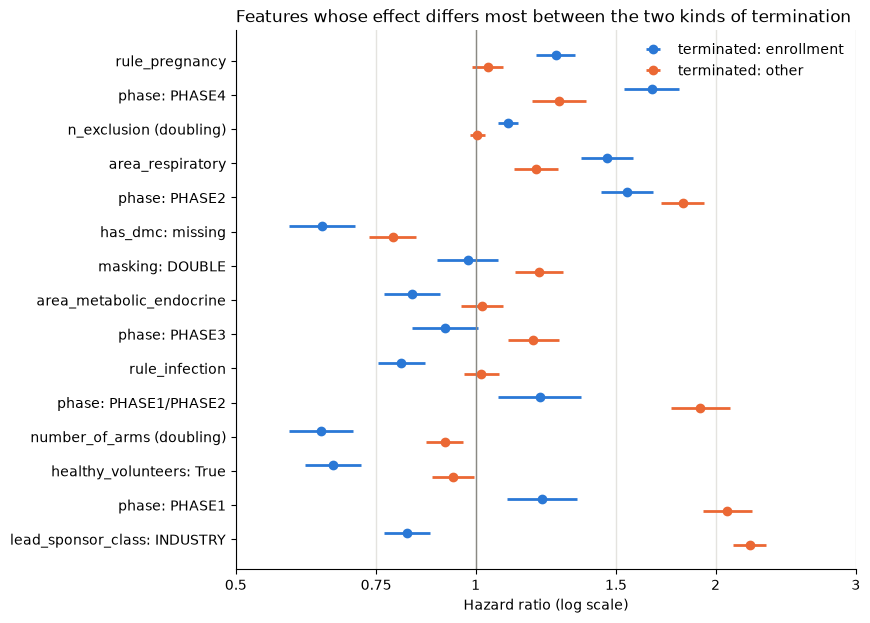

In [14]:
fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(top))
for k, offset in [(1, 0.17), (2, -0.17)]:
    f = fits[k].loc[top]
    hr, lo, hi = np.exp(f["coef"]), np.exp(f["coef"] - 1.96 * f["se"]), np.exp(f["coef"] + 1.96 * f["se"])
    ax.errorbar(hr, y + offset, xerr=[hr - lo, hi - hr], fmt="o", ms=6, color=COLORS[k], elinewidth=2,
                capsize=0, label=OUTCOMES[k])
ax.axvline(1, color="#8a8984", lw=1)
ax.set_xscale("log")
ticks = [0.5, 0.75, 1, 1.5, 2, 3]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.set_yticks(y, top)
ax.set_xlabel("Hazard ratio (log scale)")
ax.set_title("Features whose effect differs most between the two kinds of termination", loc="left")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", color="#e4e3df", lw=1)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
plt.savefig(FIG / "survival_hazard_ratios.png", bbox_inches="tight", dpi=110)
plt.show()

### Proportional hazards check

A Cox model assumes each hazard ratio is constant over follow-up. To check this for termination for low enrollment,
we refit that model on the first two years after start (trials still running at two years are censored there) and
on the time after two years (trials still running at two years). A large difference between the two windows means
the single hazard ratio averages over an effect that changes with time.

In [15]:
EARLY = 24
months, event, strata = d["months"].to_numpy(), d["outcome"].eq(1).to_numpy(float), d["start_year"].to_numpy()
late = months > EARLY
early_fit = cox_fit(X, np.minimum(months, EARLY), event * ~late, strata)
late_fit = cox_fit(X[late], months[late], event[late], strata[late])
print(f"Terminations for low enrollment: {int(event[~late].sum()):,} in the first two years, "
      f"{int(event[late].sum()):,} after")
pd.DataFrame({
    "all follow-up": np.exp(b1["coef"]),
    "first 2 years": np.exp(early_fit[0]),
    "after 2 years": np.exp(late_fit[0]),
}, index=X.columns).loc[top[::-1]].round(2)

Terminations for low enrollment: 2,894 in the first two years, 4,793 after


,all follow-up,first 2 years,after 2 years
rule_pregnancy,1.26,1.23,1.27
phase: PHASE4,1.66,1.73,1.60
n_exclusion (doubling),1.10,1.08,1.11
area_respiratory,1.46,1.59,1.36
phase: PHASE2,1.55,1.55,1.52
has_dmc: missing,0.64,0.63,0.66
masking: DOUBLE,0.98,0.94,1.01
area_metabolic_endocrine,0.83,0.84,0.82
phase: PHASE3,0.91,0.83,0.96
rule_infection,0.81,0.70,0.87


## 6. Findings so far (v0 stop reasons)

These numbers will change once the validated stop reasons replace v0.

- **Exclusion criteria raise the risk of termination for low enrollment specifically.** Each doubling of the number
  of exclusion criteria raises that hazard by 10% (HR 1.10, 95% CI 1.07–1.13) and leaves termination for other
  reasons and completion unchanged (1.01 and 1.00). Excluding pregnant participants shows the same pattern (1.26,
  against 1.04 and 0.99). These rules make trials harder to fill without changing how fast they otherwise end.
- **Industry trials are terminated more often for other reasons and less often for low enrollment.** Compared with
  OTHER (mostly academic) sponsors, the hazard ratios are 0.82 for low enrollment, 2.21 for other reasons and 1.86 for
  completion. The enrollment effect changes over time: 1.16 in the first two years and 0.62 after. That fits industry
  sponsors stopping under-enrolled trials early while academic trials keep going for years before they stop.
- **Phase 1 and healthy-volunteer trials** end faster in general, but their hazard of termination for low enrollment
  is small next to their other hazards (phase 1: 1.21 for low enrollment against 2.07 for other reasons and 1.78 for
  completion; healthy volunteers: 0.66 against 0.94 and 1.34).
- **Proportional hazards** roughly hold for most of the plotted features. The exceptions are industry sponsorship,
  phase 1/2 (1.00 in the first two years, 1.30 after) and the infection exclusion rule (0.70, then 0.87).

## 7. Still to do

1. Decide how to handle UNKNOWN trials (section 3).
2. After notebook 07, switch `REASON_COL` to the validated stop reasons, rerun, and rewrite section 6.
3. If the industry-sponsor effect goes in the report, let it change at two years (an interaction with an
   after-two-years indicator), since it fails the proportional hazards check.